# 质谱：同位素包络与分辨率

这是明确给出参数的物理教学模拟，没有使用实验测量，也不作为模型基准。可修改参数并重新执行，观察结果变化。

In [1]:
import io, json, sys
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'openmolspec_bench').is_dir())
sys.path.insert(0, str(root/'src'))
import matplotlib.pyplot as plt
from openmolspec.plotting import figure_style
figure_style()
blue, teal, grey = '#397BA6', '#178F88', '#A8B3BF'


M+1 / M ratio: 0.10815728292732234
Scope: carbon isotope contribution only; not an experimental MS/MS spectrum.


/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  func(*args, **kwargs)
/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  func(*args, **kwargs)


/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


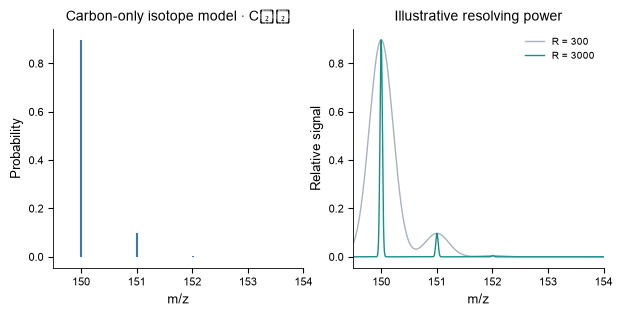

In [2]:
import numpy as np
from math import comb
carbons = 10
abundance_13c = .0107
counts = np.arange(carbons+1)
probability = np.array([comb(carbons,int(k))*abundance_13c**k*(1-abundance_13c)**(carbons-k) for k in counts])
assert np.isclose(probability.sum(),1)
base_mz = 150.
isotope_mz = base_mz + counts*1.003354835
axis = np.linspace(149.5,154,4000)
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.1))
axes[0].vlines(isotope_mz, 0, probability, color=blue, lw=1.5)
axes[0].set(xlabel='m/z', ylabel='Probability', xlim=(149.5,154), title='Carbon-only isotope model · C₁₀')
for resolution,color in [(300,grey),(3000,teal)]:
    width=base_mz/resolution/2.35482
    spectrum=(np.exp(-.5*((axis[:,None]-isotope_mz)/width)**2)*probability).sum(axis=1)
    axes[1].plot(axis,spectrum,color=color,lw=1,label=f'R = {resolution}')
axes[1].set(xlabel='m/z',ylabel='Relative signal',xlim=(149.5,154),title='Illustrative resolving power')
axes[1].legend(fontsize=7)
print('M+1 / M ratio:', float(probability[1]/probability[0]))
print('Scope: carbon isotope contribution only; not an experimental MS/MS spectrum.')

/tmp/ipykernel_1987023/2404734664.py:3: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.tight_layout(w_pad=2)
/tmp/ipykernel_1987023/2404734664.py:3: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.tight_layout(w_pad=2)
/tmp/ipykernel_1987023/2404734664.py:5: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(image,format='svg',metadata={'Date':None})
/tmp/ipykernel_1987023/2404734664.py:5: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.savefig(image,format='svg',metadata={'Date':None})


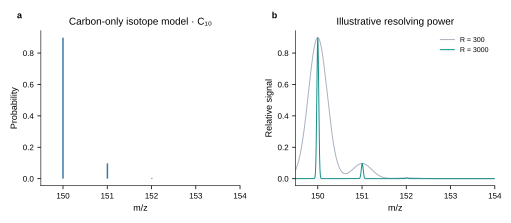

In [3]:
for index, ax in enumerate(axes):
    ax.text(-.12,1.08,chr(97+index),transform=ax.transAxes,fontsize=9,weight='bold')
fig.tight_layout(w_pad=2)
image=io.StringIO()
fig.savefig(image,format='svg',metadata={'Date':None})
display(SVG(image.getvalue()))
plt.close(fig)

[Theory](../theory/index.md) · [Inversion](../inversion/index.md) · [Tutorials](index.md)